## 1. Business Understanding   - The person will come with attroney or not to claim the insurance

## Import Neccessary Libraries

In [21]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings(action="ignore")

# 2. Data Collection

# import dataset

In [22]:
cliamants_data = pd.read_csv("cliamants.csv")
cliamants_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1335,34100,1,0.0,1.0,0.0,NaN,0.576
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


## 3. Data Understanding

In [23]:
cliamants_data.shape

(1340, 7)

In [24]:
cliamants_data.columns

Index(['CASENUM', 'ATTORNEY', 'CLMSEX', 'CLMINSUR', 'SEATBELT', 'CLMAGE',
       'LOSS'],
      dtype='object')

In [25]:
cliamants_data.isnull().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

## 4. Data Preparation

## 4.1 Data cleaning

In [26]:
cliamants_data.dropna(inplace=True)

In [27]:
cliamants_data.isnull().sum()

CASENUM     0
ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

## 4.2 Seperate Input and output

In [114]:
X = cliamants_data[['CLMSEX', 'CLMINSUR', 'SEATBELT', 'CLMAGE','LOSS']]
X


,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [115]:
y = cliamants_data['ATTORNEY']
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

## 5. Model Building

## 5.1 Split the data into Train and Test

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state= 32,shuffle=True)


## X_train,y_train  -- training data
## X_test,y_test  --- testing data

In [31]:
X_train

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
963,1.0,1.0,0.0,6.0,0.608
615,1.0,1.0,0.0,0.0,0.407
74,0.0,1.0,0.0,0.0,0.445
543,0.0,1.0,0.0,44.0,3.666
287,1.0,1.0,0.0,19.0,68.560
...,...,...,...,...,...
625,1.0,1.0,0.0,71.0,8.708
305,0.0,1.0,0.0,33.0,0.886
107,1.0,0.0,0.0,10.0,3.975
1091,0.0,0.0,0.0,47.0,6.070


In [32]:
X_test

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
1035,0.0,1.0,0.0,10.0,0.663
1255,0.0,1.0,0.0,48.0,0.455
347,1.0,1.0,0.0,56.0,3.009
121,1.0,1.0,0.0,9.0,5.813
511,1.0,1.0,0.0,8.0,3.086
...,...,...,...,...,...
354,1.0,0.0,0.0,13.0,3.091
981,0.0,1.0,0.0,1.0,0.100
178,1.0,1.0,0.0,4.0,4.117
262,0.0,0.0,0.0,6.0,0.598


In [16]:
## calling the model 

logistic_model = LogisticRegression()

## 6. Model Training

## 6.1 Logistic model fit

In [18]:
logistic_model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## 6.3 Random forest - Bagging technique - Parllel classifier

In [49]:
from sklearn.ensemble import AdaBoostClassifier,RandomForestClassifier,VotingClassifier

In [50]:
rf_classifier = RandomForestClassifier(n_estimators=100,max_depth=None)

## Grid search CV(CROSS VALIDATION) - to decide max_depth, n_estimator , criterion for random forest

**It is used for hyperparameter tuning to find optimal values for the model (i:e:- max_depth=5,criteria="entropy"). By this we can fit the random forest and train,test the model to get good performance model.**

In [62]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(estimator=rf_classifier,param_grid={"max_depth":[4,5,6,7,8,9,10],
                                                               "criterion":["gini","entropy"],
                                                              "n_estimators":[50,75,100,150]})  # n_estimators : total number of decision tree to build

grid_search.fit(X,y)

print(grid_search.best_params_)
print(grid_search.best_score_)

{'criterion': 'entropy', 'max_depth': 5, 'n_estimators': 75}
0.7344665836446659


## Here it gave n_estimators=75,max_depth=5,criterion='entropy to build the random forest model

In [75]:
rf_classifier = RandomForestClassifier(n_estimators=75,max_depth=5,criterion='entropy')

In [76]:
rf_classifier.fit(X_train,y_train)

,n_estimators,75
,criterion,'entropy'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Random forest Model building

In [78]:
y_pred_train = rf_classifier.predict(X_train)
y_pred_train

array([1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1,

In [79]:
y_pred_test = rf_classifier.predict(X_test)
y_pred_test

array([1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1])

## Random Forest Model Evaluation

In [81]:
from sklearn.metrics import accuracy_score,auc,classification_report,confusion_matrix,roc_curve,roc_auc_score

## Training data

In [82]:
print(confusion_matrix(y_train,y_pred_train))

[[374  97]
 [118 287]]


In [83]:
print(classification_report(y_train,y_pred_train))

              precision    recall  f1-score   support

           0       0.76      0.79      0.78       471
           1       0.75      0.71      0.73       405

    accuracy                           0.75       876
   macro avg       0.75      0.75      0.75       876
weighted avg       0.75      0.75      0.75       876



0.7513485885035779


Text(0, 0.5, 'True Positive Rate')

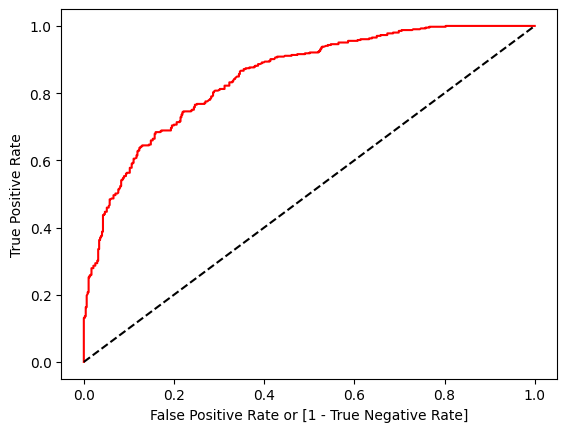

In [89]:
fpr, tpr, thresholds = roc_curve(y_train, rf_classifier.predict_proba (X_train)[:,1])

auc = roc_auc_score(y_train,y_pred_train)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='random forest model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

## for testing data

In [85]:
accuracy_score(y_test,y_pred_test)

0.7181818181818181

In [86]:
print(confusion_matrix(y_test,y_pred_test))

[[77 30]
 [32 81]]


In [87]:
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

           0       0.71      0.72      0.71       107
           1       0.73      0.72      0.72       113

    accuracy                           0.72       220
   macro avg       0.72      0.72      0.72       220
weighted avg       0.72      0.72      0.72       220



0.7182201637581672


Text(0, 0.5, 'True Positive Rate')

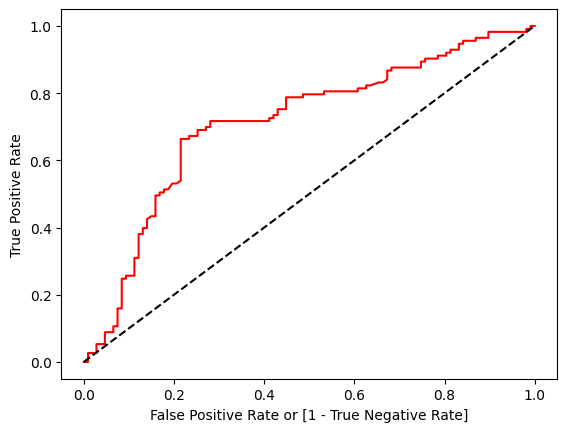

In [90]:
fpr, tpr, thresholds = roc_curve(y_test, rf_classifier.predict_proba (X_test)[:,1])

auc = roc_auc_score(y_test,y_pred_test)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='random forest model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

## 6.4 Ada boost - Boosting Technique - Sequential Algorithm

In [91]:
ada_boost_classifier = AdaBoostClassifier()

In [95]:
ada_boost_classifier.fit(X_train,y_train)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,None


In [97]:
y_pred_train = ada_boost_classifier.predict(X_train)
y_pred_train

array([1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0,
       1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1,
       1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1,

In [98]:
y_pred_test = rf_classifier.predict(X_test)
y_pred_test

array([1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1])

## Ada Boost Model evaluation

In [100]:
from sklearn.metrics import accuracy_score,auc,classification_report,confusion_matrix,roc_curve,roc_auc_score

## Training data

In [101]:
print(confusion_matrix(y_train,y_pred_train))

[[360 111]
 [128 277]]


In [102]:
print(classification_report(y_train,y_pred_train))

              precision    recall  f1-score   support

           0       0.74      0.76      0.75       471
           1       0.71      0.68      0.70       405

    accuracy                           0.73       876
   macro avg       0.73      0.72      0.72       876
weighted avg       0.73      0.73      0.73       876



0.7241409137375167


Text(0, 0.5, 'True Positive Rate')

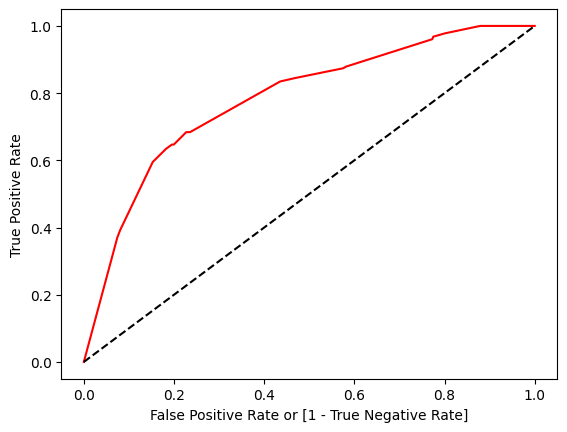

In [105]:
fpr, tpr, thresholds = roc_curve(y_train, ada_boost_classifier.predict_proba (X_train)[:,1])

auc = roc_auc_score(y_train,y_pred_train)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='ada boost model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

## Testing Data

In [106]:
accuracy_score(y_test,y_pred_test)

0.7181818181818181

In [107]:
print(confusion_matrix(y_test,y_pred_test))

[[77 30]
 [32 81]]


0.7182201637581672


Text(0, 0.5, 'True Positive Rate')

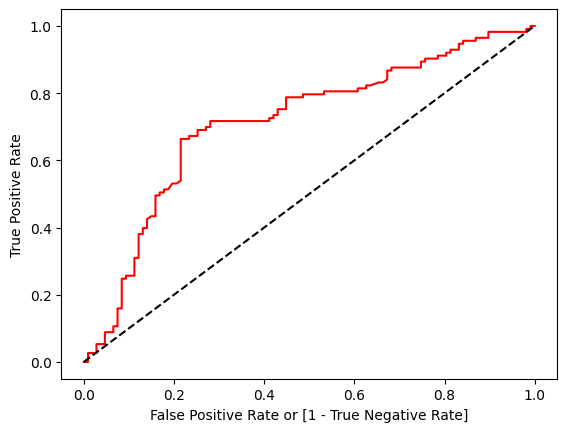

In [108]:
fpr, tpr, thresholds = roc_curve(y_test, rf_classifier.predict_proba (X_test)[:,1])

auc = roc_auc_score(y_test,y_pred_test)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='Ada boost model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

## 6.5 Stacking technique - NOT SUGGESTED ALGORITHM - BECAUSE IT CAUSE HIGH COMPUTATIONAL TIME

In [110]:
from sklearn.neighbors import KNeighborsClassifier

In [118]:
logistic_classifier = LogisticRegression()
decision_tree_classifier = DecisionTreeClassifier()
knn_classifier = KNeighborsClassifier()


voting_classifier = VotingClassifier(estimators = 
                                     [("logistic_model",logistic_classifier),
                                      ("decision_model",decision_tree_classifier),
                                      ("Knn_model",knn_classifier)
                                     ])


In [119]:
voting_classifier.fit(X, y)

,estimators,"[('logistic_model', ...), ('decision_model', ...), ...]"
,voting,'hard'
,weights,None
,n_jobs,None
,flatten_transform,True
,verbose,False
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True


In [121]:
y_pred = voting_classifier.predict(X)

In [122]:
accuracy_score(y,y_pred)

0.8394160583941606

## 6.2 Decision Tree

In [109]:
from sklearn.tree import DecisionTreeClassifier

# calling the decision tree model

In [18]:
dt_model =  DecisionTreeClassifier()

## Fit the decision tree

In [19]:
dt_model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


 ## 7. Model Testing

## Predict training output for decision tree

In [20]:
y_pred_train = dt_model.predict(X_train)
y_pred_train

array([1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1,
       0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1,
       1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1,
       1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1,

In [34]:
## Predict testing output for decision tree

In [21]:
y_pred_test = dt_model.predict(X_test)
y_pred_test

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0,
       1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1])

## 8. Model Evaluation

In [22]:
from sklearn.metrics import accuracy_score,auc,classification_report,confusion_matrix,roc_curve,roc_auc_score

## 8.1 Training Data's evaluation metrics

## confusion metrics

In [23]:
print(confusion_matrix(y_train,y_pred_train))

[[471   0]
 [  3 402]]


In [24]:
print(classification_report(y_train,y_pred_train))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       471
           1       1.00      0.99      1.00       405

    accuracy                           1.00       876
   macro avg       1.00      1.00      1.00       876
weighted avg       1.00      1.00      1.00       876



## ROC curve

## AUC curve

## for training data

## here it is 99%

0.9962962962962962


Text(0, 0.5, 'True Positive Rate')

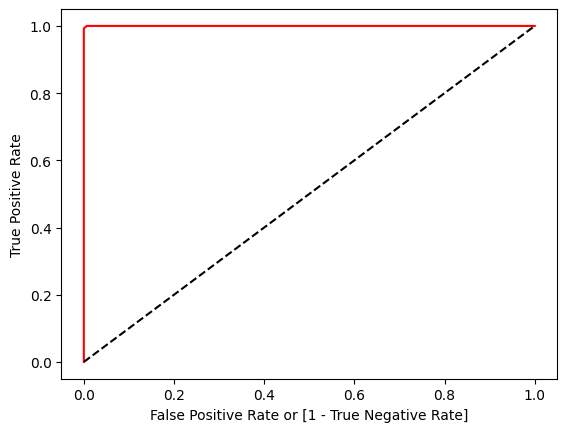

In [25]:
fpr, tpr, thresholds = roc_curve(y_train, dt_model.predict_proba (X_train)[:,1])

auc = roc_auc_score(y_train,y_pred_train)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

## below accuracy for unseen data y_test

In [26]:
accuracy_score(y_test,y_pred_test)

0.5772727272727273

In [27]:
print(confusion_matrix(y_test,y_pred_test))

[[67 40]
 [53 60]]


In [28]:
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

           0       0.56      0.63      0.59       107
           1       0.60      0.53      0.56       113

    accuracy                           0.58       220
   macro avg       0.58      0.58      0.58       220
weighted avg       0.58      0.58      0.58       220



## ROC curve

## AUC curve

## for testing data

## here it is 58%

0.5785708378132495


Text(0, 0.5, 'True Positive Rate')

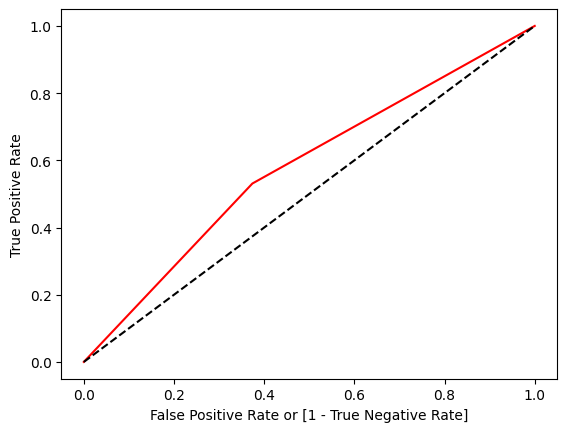

In [30]:
fpr, tpr, thresholds = roc_curve(y_test, dt_model.predict_proba (X_test)[:,1])

auc = roc_auc_score(y_test,y_pred_test)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

## After doing the decision tree , the unseen data is in false positive rate

## Here the training data has high accuracy means LOW ERROR = LOW BIAS , testing data has less accuracy means HIGH ERROR = HIGH VARIANCE,
## SO LOW BIAS(99% accuracy) + HIGH VARIANCE(only 58% accuracy) = OVERFITTING

## THIS IS CALLED OVERFITING PROBLEM OR THIS MODEL GOT OVERFITTED

## NOTE: WE ALWAYS EXCEPT GENERALIZED MODEL

## Bias variance

**Bias - always associated with Training data**


**variance - always associated with Testing data**

## LOW BIAS + HIGH VARIANCE = OVERFITTING

## HIGH BIAS + LOW VARIANCE = UNDERFITTING

## LOW BIAS + LOW VARIANCE = GENERALISED MODEL  ---> WE NEED THIS MODEL ONLY

## sO THERE IS ALWAYS TRADEOFF BETWEEN BIAS AND VARIANCE



In [31]:
from sklearn.tree import DecisionTreeClassifier

## To resolve overfitting we are using max_depth(means the tree will grow until particular depth to leaf node) ---> refer claimants _prediction_avoid_overfitting py file in this folder for script